# Машинное обучение, ФКН ВШЭ

# Практическое задание 6. Бустинговое

## Общая информация

Дата выдачи: 11.05.2026

Мягкий дедлайн: 25.05.2026 23:59 MSK

Жёсткий дедлайн: 31.05.2026 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-06-Username.ipynb
* Модуль boosting.py

Username — ваша фамилия на латинице

Выполнила: Смахтина Яна, 23.Б02

Баллов: 15,5 / 10 :)

## О задании

В этом задании вам предстоит вручную запрограммировать один из самых мощных алгоритмов машинного обучения — бустинг. Однако с большой силой приходит и большая ответственность, поэтому придется научиться им пользоваться

In [1]:
from warnings import filterwarnings
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

sns.set(style='darkgrid')
filterwarnings('ignore')

Мы будем работать с датасетом по предсказанию гендера. Никакие фичи мы придумывать не будем, но если вам интересно, в датасете имеется:

- region — регион, в котором проводили опрос
- age — возраст опрошенного
- year — год опроса
- race — этническая принадлежность
- sch — количество классов образования
- empstat — статус трудоустройства
- occ — код профессии
- ind — код индустрии, в которой человек работает
- annhrs — число часов работы в год
- hrwage — почасовая оплата
- icwage — суммарная оплата в год
- occupation — должность

Целевая метрика ROC-AUC, потому что мы непритязательны и это не фокус этой домашки



In [2]:
df = pd.read_parquet("hw6_dataset.pq")

X = df.drop("sex", axis=1)
y = df["sex"]

Пока что мы временно выкинем колонку с должностью, но мы к ней обязательно вернемся

Разделим на обучающую, валидационную и тестовую выборки по годам, чтобы предсказывать будущее, а не прошлое

In [3]:
X_train = X[X["year"] < 2011].drop("occupation", axis=1).values
y_train = y[X["year"] < 2011].values

X_valid = X[X["year"] == 2011].drop("occupation", axis=1).values
y_valid = y[X["year"] == 2011].values

X_test = X[X["year"] == 2013].drop("occupation", axis=1).values
y_test = y[X["year"] == 2013].values

X_train.shape, X_valid.shape, X_test.shape

((236640, 10), (53857, 10), (53790, 10))

Домашнее задание имеет нелинейную структуру. В нём есть <font color='lightcoral'>📌 **обязательные**</font> части, без которых будет тяжко <font color='lightcoral'>**(6 баллов)**</font>, и целая куча 💠 **опциональных**, которыми можно добить оценку до 10, делайте то, что нравится больше! **Музыкальный бонус** идёт отдельно, за него можно получить ещё 0.5 балла.

---

## 📌 Задание 1. Базовый градиентный бустинг (4 балла)

Это задание <font color='lightcoral'>**📌 обязательное**</font>, без него домашка не имеет смысла! Ещё раз обращаем внимание, что **опциональные** задания помечены 💠

Первая часть посвящена реализации собственного градиентного бустинга. Обращаем внимание, что пользоваться готовыми реализациями <font color='lightcoral'>**нельзя**</font>, если специально не оговорено. На все <font color='lightcoral'>**вопросы**</font> должен быть <font color='lightcoral'>**ответ**</font>. В заданиях, где нужно делать параметры, часто есть референсы из других библиотек. На случай, если объяснение из ноутбука непонятно, советуем обратиться к соответствующей документации и пощупать, как это делается там

Вам нужно дописать код в файлике `boosting.py`. Для вас уже подготовлен шаблон класса `Boosting`, вы можете менять его по своему усмотрению.

### Инструкции для функций:

#### `__init__`

Существующие параметры:
- `base_model_class` — класс базовой модели нашего бустинга
- `base_model_params` — словарь с гиперпараметрами для базовой модели
- `n_estimators` — какое количество базовых моделей нужно обучить
- `learning_rate` — темп обучения, должен быть из полуинтервала $(0, 1]$
- `random_state`— в роли рандом стейта
- `verbose` — для тех, кому не нравится загадочность, можно включить и увидеть, сколько еще ждать конца обучения

#### `fit`

В `fit` приходит выборка, на которой мы обучаем новые базовые модели

1. Сначала нам нужно сделать какую-то нулевую модель, сделать предсказания (в шаблоне это нулевая модель, соответственно предсказания это просто `np.zeros`).
2. После этого нужно обучить `n_estimators` базовых моделей (как и на что обучаются базовые модели смотрите в лекциях и семинарах).
3. После каждой обученной базовой модели мы должны обновить текущие предсказания, посчитать ошибку на выборке (используем `loss_fn` для этого) и найти новую оптимальную гамму

#### `partial_fit`

В `partial_fit` передаются данные `X: np.ndarray, y: np.ndarray` для одного шага бустинга: обучаем следующую базовую модель на антиградиенте и обновляем ансамбль.

#### `predict_proba`

В `predict_proba` приходит любая выборка, нужно предсказать вероятности для неё. Суммируем предсказания базовых моделей на этой выборке (не забываем про гаммы) и накидываем сигмоиду

In [4]:
import importlib
import boosting

In [5]:
importlib.reload(boosting)

from boosting import Boosting, GHTree, Quantizer, find_best_split

### Проверка кода

In [6]:
boosting = Boosting(
    verbose=True,
    base_model_params=dict(max_depth=5),
    n_estimators=50,
    random_state=69, # не забывайте фиксировать, пожалуйста
)

boosting.fit(X_train, y_train)

assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2), "prediction shapes are incorrect"
assert np.array_equal(boosting.history["train_loss"], np.sort(boosting.history["train_loss"])[::-1]), "train loss is not decreasing"

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)

# здесь и далее работаем с метрикой ROC-AUC
print(f'Train ROC-AUC {boosting.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {boosting.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {boosting.score(X_test, y_test):.4f}')

  0%|          | 0/50 [00:00<?, ?it/s]

Train ROC-AUC 0.8013
Valid ROC-AUC 0.7247
Test ROC-AUC 0.7196


---

## Задание 2. Имплементация гиперпараметров (📌 1 балл |💠 8.25 балла)

Бустинг, как метод агрегации, предлагает несколько вариантов регуляризации.

В этом пункте мы будем делать кучу самых разных гиперпараметров, каждый из них прекрасен по-своему, но полноценно их эффект получится ощутить лишь на этапе их перебора (кроме, пожалуй, `rsm`), поэтому делать третью часть до второй не рекомендуется

<font color='lightcoral'>**Важно!**</font> После добавления каждого параметра проверьте, как это повлияет на качество. Специально крутить параметры не нужно, но важно увидеть, что перформанс модели изменился, в худшую или в лучшую сторону. Для этого какие-то параметры нужны, пусть и от балды, <font color='lightcoral'>**гарантии, что дефолтные параметры подойдут, нет**</font>. Лучше всего это видно по графикам обучения <font color='lightcoral'>**на трейне и валидации**</font>, рекомендуется смотреть именно на них

### 📌 2.1. Борьба с переобучением (0.5 балла)

Как известно, бустинги бывают склонны к переобучению. Чтобы этого не допустить, можно контролировать процесс обучения и проверять критерий останова на валидации прямо во время обучения. Реализуйте такую процедуру, не забудьте, что всю предобработку, что вы будете в дальнейшем делать для трейна, нужно будет повторить на валидации

Добавьте в вашу модель:
- `early_stopping_rounds: int | None = 0` — число раундов для критерия останова. Если качество ухудшается на протяжении всех раундов подряд, останавливаем обучение
- `eval_metric: str | None = None` — метрика, на которую смотрим, чтобы остановить обучение, может быть ключом из `model.history`
- `plot_history(self, keys: str | Iterable[str])` — метод, который строит график изменения метрики по ключам из `model.history`

И конкретно в метод `model.fit`:
- `eval_set: tuple[np.ndarray] | None = None` — валидационная выборка `X_valid: np.ndarray, y_valid: np.ndarray`, на которой будем проверять переобучение
- `use_best_model: bool = False` — использовать лучшую модель, или нет. Если да, то отрезаем гаммы и модели вплоть до той, на которой остановились, минус `early_stopping_rounds`, т.е самой лучшей, после которой качество только падает

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td colspan="3" align="center"><code>early_stopping_rounds</code>, <code>eval_set</code></td>
</tr>
</table>

</div>

Продемонстрируйте, что все работает

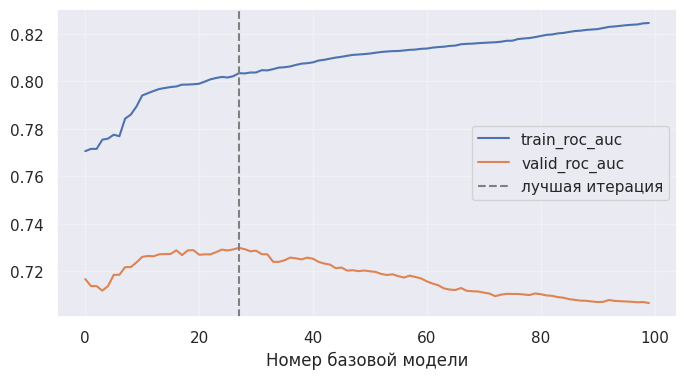

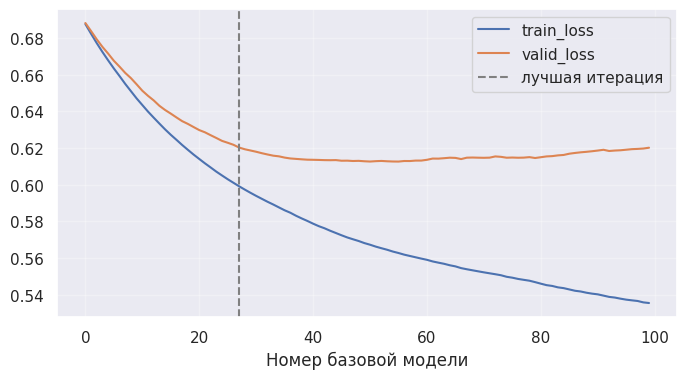

Без остановки: обучено 100 моделей, лучшая итерация 27
С остановкой:  обучено 38 моделей, лучшая итерация 27, в ансамбле 28
Valid ROC-AUC без остановки: 0.7066, с остановкой: 0.7299
Test  ROC-AUC без остановки: 0.6990, с остановкой: 0.7245


In [7]:
common = dict(base_model_params=dict(max_depth=5), n_estimators=100, learning_rate=0.1, random_state=69, verbose=False)

no_stop = Boosting(**common)
no_stop.fit(X_train, y_train, eval_set=(X_valid, y_valid))

early = Boosting(early_stopping_rounds=10, eval_metric="valid_roc_auc", **common)
early.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=True)

no_stop.plot_history(["train_roc_auc", "valid_roc_auc"])
no_stop.plot_history(["train_loss", "valid_loss"])

print(f"Без остановки: обучено {len(no_stop.history['valid_roc_auc'])} моделей, лучшая итерация {no_stop.best_iteration_}")
print(f"С остановкой:  обучено {len(early.history['valid_roc_auc'])} моделей, лучшая итерация {early.best_iteration_}, в ансамбле {len(early.models)}")
print(f"Valid ROC-AUC без остановки: {no_stop.score(X_valid, y_valid):.4f}, с остановкой: {early.score(X_valid, y_valid):.4f}")
print(f"Test  ROC-AUC без остановки: {no_stop.score(X_test, y_test):.4f}, с остановкой: {early.score(X_test, y_test):.4f}")

### 📌 2.2. Категории 2.0 (0.5 балла)

Пока что для простоты картины мы игнорировали категориальные признаки. <font color='#c4bf0a'>**CatBoost**</font> в частности предлагает один из самых эффективных и быстрых вариантов кодировки категорий, который мы попробуем повторить

> Основная идея в том, что важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:

$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)]}
$$


Добавьте в модель вот это:
- `cat_features: Iterable | None` — категориальные признаки для кодирования
- `_cat_fit(self, X: np.array, y: np.ndarray)` — внутренний метод для построения счетчиков
- `_cat_transform(self, X: np.ndarray)` — внутренний метод для применения счетчиков

Лмбо сделайте энкодер отдельным классом с аналогичными методами `fit` и `transform`, это даже лучше. Его нужно прогнать всего раз для каждой из выборок

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>cat_features</code></td>
</tr>
</table>

</div>

Закодируйте переменные, которые вы хотите считать категориальными, с помощью счётчиков (готовые реализации брать нельзя) и покажите эффект. Помните, что все должно быть векторизовано и красиво

In [8]:
# вернем occupation туда, где ему самое место, но это не единственная кат фича!

X_train = X[X["year"] < 2011].values
X_valid = X[X["year"] == 2011].values
X_test = X[X["year"] == 2013].values

In [9]:
occupation_idx = X.columns.get_loc("occupation")
occ_idx = X.columns.get_loc("occ")
numeric_idx = [j for j in range(X.shape[1]) if j != occupation_idx]

experiments = {
    "без категорий": (numeric_idx, None),
    "occupation": (list(range(X.shape[1])), [occupation_idx]),
    "occupation + occ": (list(range(X.shape[1])), [occupation_idx, occ_idx]),
}

rows = []
for name, (columns, cat_features) in experiments.items():
    cat_positions = None if cat_features is None else [columns.index(j) for j in cat_features]
    model = Boosting(
        base_model_params=dict(max_depth=5), n_estimators=100, learning_rate=0.1,
        early_stopping_rounds=15, eval_metric="valid_roc_auc",
        cat_features=cat_positions, random_state=69, verbose=False,
    )
    model.fit(X_train[:, columns], y_train, eval_set=(X_valid[:, columns], y_valid), use_best_model=True)
    rows.append({
        "признаки": name,
        "моделей": len(model.models),
        "train ROC-AUC": model.score(X_train[:, columns], y_train),
        "valid ROC-AUC": model.score(X_valid[:, columns], y_valid),
        "test ROC-AUC": model.score(X_test[:, columns], y_test),
    })

pd.DataFrame(rows).round(4)

,признаки,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC
0,без категорий,28,0.8035,0.7299,0.7245
1,occupation,7,0.8328,0.7740,0.7702
2,occupation + occ,2,0.8700,0.8068,0.8008


In [10]:
common_params = dict(
    base_model_params=dict(max_depth=5), n_estimators=100, learning_rate=0.1,
    early_stopping_rounds=15, eval_metric="valid_roc_auc", cat_features=[occupation_idx, occ_idx],
)


def compare(configs, use_best_model=True, **common):
    rows = []
    for name, params in configs.items():
        start = time.time()
        model = Boosting(random_state=69, verbose=False, **{**common, **params})
        model.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=use_best_model)
        rows.append({
            "конфигурация": name,
            "моделей": len(model.models),
            "train ROC-AUC": model.score(X_train, y_train),
            "valid ROC-AUC": model.score(X_valid, y_valid),
            "test ROC-AUC": model.score(X_test, y_test),
            "время, с": time.time() - start,
        })
    return pd.DataFrame(rows).round(4)

### 💠 2.3. Категории 3.0 (0.5 балла)

Увы, закодированные признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем утечку целевой переменной в признаки, но с этим можно жить, в частности $\text{OrderedBoosting}$ это одна из главных фишек <font color='#c4bf0a'>**CatBoost**</font>, была. Почитайте [статью](https://arxiv.org/pdf/1706.09516), она интересная

Реализуйте подсчет счетчиков так, чтобы кодировка категории была только по объектам. расположенным выше в датасете (например, если выборка отсортирована каким-либо образом)

Методы добавлять не нужно, разве что очень хочется, предполагается, что это дефолтное поведение бустинга

In [11]:
rows = []
for name, ordered in [("обычные счетчики", False), ("упорядоченные счетчики", True)]:
    model = Boosting(**{**common_params, "ordered_cat": ordered}, random_state=69, verbose=False)
    model.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=True)
    rows.append({
        "счетчики": name,
        "моделей": len(model.models),
        "train ROC-AUC": model.score(X_train, y_train),
        "valid ROC-AUC": model.score(X_valid, y_valid),
        "test ROC-AUC": model.score(X_test, y_test),
    })

pd.DataFrame(rows).round(4)

,счетчики,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC
0,обычные счетчики,2,0.8700,0.8068,0.8008
1,упорядоченные счетчики,10,0.8724,0.8099,0.8037


**Комментарий к 2.3.** Упорядоченные счетчики (для объекта берутся только предыдущие объекты в случайном порядке) убирают утечку собственного таргета в признак: valid ROC-AUC 0.8068 -> 0.8099, test 0.8008 -> 0.8037, и ранняя остановка срабатывает уже не на второй модели, а на десятой. Train ROC-AUC при подсчете через `score` считается по обычным счетчикам, поэтому его не стоит сравнивать с обучением напрямую.

### 💠 2.4. Категории 4.0, L2 и боль (2 балла)

Но погодите, вы ещё ничего не видели! Счётчики это замечательный способ кодирования категорий, но у них есть ровно один недостаток — после кодировки признаки становятся числовыми, а если вы помните дз5, категориальные и числовые признаки обрабатываются деревьями чуть-чуть иначе.

<font color="#53c96c">**LightGBM**</font> и <font color="#2f82d4">**XGBoost**</font> решают этот вопрос не так, как <font color='#c4bf0a'>**CatBoost**</font>. Сейчас будем разбираться... И будет это тяжело, потому что отдебажить это не получится вплоть до самого конца.

Для этого пункта вам придётся стряхнуть пыль с вашей [реализации дерева](https://github.com/esokolov/ml-course-hse/blob/master/ml1-2026-spring/homework-practice/homework-practice-05-trees/hw5code.py) из дз5. Будем верить, что она написана красиво и хорошо масштабируется на новые МЛьные приключения.

#### 2.4.1. Настоящий критерий информативности (0.5 балла)

Современные реализации бустинга не используют дефолтные критерии информативности, вроде энтропии или дисперсии. Параметр `gamma`, который за нас любезно подбирается в классе `Boosting` это немного устаревший способ выбора весов (лет так на 25).

На лекции обсуждается, что получить формулу для обучения нового дерева $b_n(x)$ можно, если разложить исходную задачу обучения бустинга в ряд Тейлора. Там же показано, что при обучении на один лишь сдвиг $s_i(x)$ мы полагаем кривизну $h_i(x) = \frac{\partial^2 L}{\partial z^2}$ константной. Но можем и не полагать, как [сделали](https://arxiv.org/pdf/1603.02754) авторы уже немолодого <font color="#2f82d4">**XGBoost**</font>.

Критерий информативности в таком случае имеет вид:

$$
H(R_m) = \frac{G_l^2}{H_l + \lambda} + \frac{G_r^2}{H_r + \lambda} - \frac{G_m^2}{H_m + \lambda}
$$

- $G$ — сумма градиентов
- $H$ — сумма гессианов
- $\lambda$ — коэффициент регуляризации
- индексы $_l$, $_r$, $_m$ — левый, правый, исходный узел дерева соответственно

> Кривизна позволяет нам подстроиться под каждый объект, когда мы делаем шаг градиентного бустинга. $\gamma$ в таком случае оказывается не нужна, она не умеет подстраивать шаг индивидуально. Более того, сюда можно сразу же встроить $L_2$ регуляризацию, что мы и сделаем.     
Наконец, если перейти от объектов к градиентам и гессианам, внезапно можно вообще забить на то, числовой признак или категориальный, мы же всё равно оцениваем градиент, то есть сплит подбираем напрямую из задачи. Велико!

Текущая задача: модифицировать функцию `find_best_split`. Считайте, что параметры `grad_vector` и `hess_vector` в неё уже передаются. Градиент мы считать уже умеем, с гессианом разберёмся попозже

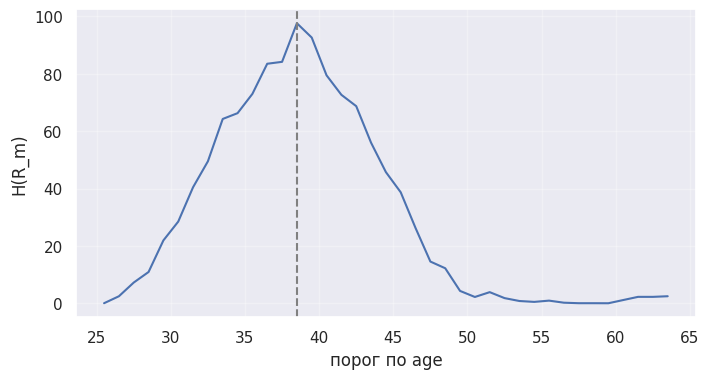

лучший порог: 38.5, значение критерия: 97.65


In [12]:
y_pm = y_train.astype(float)
age = X_train[:, X.columns.get_loc("age")].astype(float)

grad = -y_pm * 0.5
hess = np.full(len(y_pm), 0.25)

thresholds, criteria, threshold_best, criterion_best = find_best_split(age, grad, hess, l2=1.0)

plt.figure(figsize=(8, 4))
plt.plot(thresholds, criteria)
plt.axvline(threshold_best, color="gray", linestyle="--")
plt.xlabel("порог по age")
plt.ylabel("H(R_m)")
plt.grid(True, alpha=0.3)
plt.show()

print(f"лучший порог: {threshold_best}, значение критерия: {criterion_best:.2f}")

#### 2.4.2. Я посадил дерево (0.75 балла)

Теперь, когда критерий у нас есть, наступает следующий логический шаг - пихнуть его в дерево. Предсказания будут иметь следующий вид:

$$b(R) = \frac{1}{|R|}\sum_{y_i \in R} \frac{\nabla(y_i)}{(\nabla^2(y_i) + \lambda )}$$

Это сумма градиентов делить на сумму гессианов + коэффициент регуляризации. В случае $\nabla^2(y_i) = 1$ и нулевой регуляризации вырождается в наш самый обыкновенный бустинг. Мы ведь помним, что каждое дерево в нём обучается на антиградиент.

Что делать то?

- добавить параметр `l2: float | None = 1.0` в вашу реализацию дерева
- подправить предсказания по формуле выше, сейчас они считаются для классификации, а не для регрессии (должно быть идентично и для чисел, и для категорий)
- категории нужно занумеровать, это делается за вас в дереве, но не забудьте пожалуйста
- в `fit_node` должны поступать градиенты и гессианы, в левый и правый узел после разбиения тоже, уже для соответствующих левой и правой подвыборок

> Строго говоря, <font color="#53c96c">**LightGBM**</font> перебирает категории по критерию Фишера, который группирует категории по градиентам. Это один из видов квантизации, которая будет чуть ниже. Делать это не надо, но если любопытно, то [почитайте](https://lightgbm.readthedocs.io/en/latest/Features.html#optimal-split-for-categorical-features)

In [13]:
from sklearn.tree import DecisionTreeRegressor

numeric = X_train[:, numeric_idx].astype(float)
antigrad = y_pm * 0.5

ours = GHTree(max_depth=5, l2=0.0).fit(numeric, antigrad)
reference = DecisionTreeRegressor(max_depth=5, random_state=69).fit(numeric, antigrad)
print("макс. расхождение с DecisionTreeRegressor при гессиане 1 и l2 = 0:",
      np.abs(ours.predict(numeric) - reference.predict(numeric)).max())

tree = GHTree(max_depth=5, l2=1.0, cat_features=[occ_idx]).fit(X_train, antigrad, hess)
print("категориальные столбцы:", list(X.columns[tree.is_cat_]))
print("число узлов:", len(tree.nodes_))
pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).round(3)

макс. расхождение с DecisionTreeRegressor при гессиане 1 и l2 = 0: 0.0
категориальные столбцы: ['occ', 'occupation']
число узлов: 63


,0
occ,0.956
annhrs,0.032
occupation,0.012
age,0.000
region,0.000
year,0.000
race,0.000
empstat,0.000
sch,0.000
hrwage,0.000


#### 2.4.3. Момент истины (0.75 балла)

Наконец, осталось запихнуть это дело в бустинг. Алгоритм будет работать точно так же. Если вы корректно его написали, поменять потребуется немного, а именно:

- добавить гиперпараметр `l2: float | None = 0.0`
- добавить метод `self.hess_fn = lambda y, z: ...`, который будет считать гессиан для бинарной кросс-энтропии
- приравнять оптимальную гамму к единице, если `l2` не равен 0
- передавать гредиенты и гессианы в базовую модель, если у неё есть параметр `l2` и он не равен 0
- гессиан лучше клипать, иначе можно внезапно поделить на 0 при маленьком `l2`
- не забудьте, что передавать надо антиградиенты, а не просто градиенты, иначе выйдет что-то не то

Покажите, что оно работает...

In [14]:
newton_configs = {
    "sklearn-дерево, gamma по сетке, счетчики": dict(
        base_model_class=DecisionTreeRegressor, base_model_params=dict(max_depth=5),
        learning_rate=0.1, l2=0.0, cat_features=[occupation_idx, occ_idx]),
    "GHTree, l2=1, счетчики": dict(
        base_model_class=GHTree, base_model_params=dict(max_depth=5),
        learning_rate=0.3, l2=1.0, cat_features=[occupation_idx, occ_idx]),
    "GHTree, l2=1, occupation как категория в дереве": dict(
        base_model_class=GHTree, base_model_params=dict(max_depth=5, cat_features=[occupation_idx]),
        learning_rate=0.3, l2=1.0),
}

compare(newton_configs, n_estimators=100, early_stopping_rounds=15, eval_metric="valid_roc_auc")

,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,"sklearn-дерево, gamma по сетке, счётчики",2,0.8700,0.8068,0.8008,15.3044
1,"GHTree, l2=1, счётчики",2,0.8730,0.8075,0.8016,23.9193
2,"GHTree, l2=1, occupation как категория в дереве",3,0.8375,0.7768,0.7728,31.1371


**Комментарий к 2.4.** `GHTree` при гессиане 1 и `l2 = 0` совпадает с `DecisionTreeRegressor`, а при `l2 = 1` и гессианах значение в листе равно сумме антиградиентов, деленной на сумму гессианов плюс `l2`. Категории нумеруются внутри дерева и упорядочиваются по `G / (H + l2)`, после чего делятся порогом, поэтому для сплита не важно, числовой признак или категориальный. В boosting при `l2 != 0` и наличии у базовой модели параметра `l2` в дерево передаются гессианы, а `gamma` берется равной 1. Деревья по градиентам и гессианам со счетчиками дали 0.8075 / 0.8016 против 0.8068 / 0.8008 у sklearn-дерева. Если отдать дереву `occupation` как категорию без счетчиков, получается хуже (0.7768 / 0.7728): категорийное разбиение по 22 значениям переобучается быстрее, чем счетчик.

### 💠 2.5. Бутстрап (1.25 балла)</span>

Как известно, при обучении базовых алгоритмов в беггинге, используется бутстрапированная выборка. Звучит хайпово, почему бы не попробовать сделать то же самое в бустинге?

> Идея, которая за этим стоит проста — бустинги переобучаются, как черти. Бутстрап же может сделать процесс куда более робастным и быть одним из способов регуляризации, а заодно уменьшить время обучения, в случае бутстрапа Бернулли

#### 2.5.1. Бутстрап дефолтный (0.75 балла)

Вам нужно реализовать параметры:
- `subsample: float = 1.0` — доля объектов, на которой будет обучаться базовая модель (какую часть составляет бутстрапная выборка от исходной обучающей). Соответствует бутстрапу типа `Bernoulli`. Каждый объект либо входит в подвыборку, либо нет
- `bagging_temperature: float = 1.0` — температура для генерации весов. Соответствует бутстрапу типа `Bayesian`. Каждому объекту присваивается вес $w$, который получается из температуры $t$, после чего объект, в количестве $w$, попадает в выборку.      
$w = (-\log(X))^t$, где $X \sim {U[0, 1]}$      
Таким образом можно сделать симуляцию повторений, обобщив на непрерывный случай. Обычный бутстрап не умеет сэмплировать дробное число объектов, но можно сделать примерно то же самое, если размножить объект $w$ раз, либо присвоить вес. Подумайте, как это корректно реализовать в бустинге
- `bootstrap_type: str | None = 'Bernoulli'` — тип бутстрапа

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>subsample</code>, <code>-</code></td>
<td align="center"><code>subsample</code>, <code>bagging</code></td>
<td align="center"><code>subsample</code>, <code>bootstrap_type</code></td>
</tr>
</table>

</div>

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** как бутстрап может помочь в обучении с точки зрения смещения, разброса и вообще?

**Ответ:** бустинг может снижать смещение, но при этом быть склонным к высокому разбросу: каждое следующее дерево исправляет остатки предыдущих, поэтому ансамбль легко подстраивается и под шум. Бутстрап обучает каждое дерево на слегка разной выборке. Ошибки деревьев становятся менее скоррелированными, и сумма деревьев получает меньший разброс, как при бэггинге. Платой служит небольшой рост смещения: дерево видит меньше данных. Дополнительные плюсы: регуляризация, ускорение обучения (меньше объектов на шаг) и шум в градиентах, который мешает слишком быстро подгоняться под обучающую выборку.

На наших данных эффект небольшой: valid ROC-AUC без бутстрапа 0.8068, Bernoulli с `subsample=0.8` 0.8081, Bayesian с `bagging_temperature=0.5` 0.8069. При слишком сильном шуме (Bayesian, `bagging_temperature=3`) качество падает до 0.8022: выигрыш от снижения разброса уже не компенсирует рост смещения.

</div>

In [15]:
bootstrap_configs = {
    "без бутстрапа": dict(),
    "Bernoulli, subsample=0.5": dict(bootstrap_type="Bernoulli", subsample=0.5),
    "Bernoulli, subsample=0.8": dict(bootstrap_type="Bernoulli", subsample=0.8),
    "Bayesian, temperature=0.5": dict(bootstrap_type="Bayesian", bagging_temperature=0.5),
    "Bayesian, temperature=1": dict(bootstrap_type="Bayesian", bagging_temperature=1.0),
    "Bayesian, temperature=3": dict(bootstrap_type="Bayesian", bagging_temperature=3.0),
}

compare(bootstrap_configs, **common_params)

,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,без бутстрапа,2,0.8700,0.8068,0.8008,16.1063
1,"Bernoulli, subsample=0.5",7,0.8727,0.8071,0.8008,14.7717
2,"Bernoulli, subsample=0.8",12,0.8740,0.8081,0.8016,22.9053
3,"Bayesian, temperature=0.5",7,0.8725,0.8069,0.8005,22.7414
4,"Bayesian, temperature=1",12,0.8738,0.8061,0.7995,26.6390
5,"Bayesian, temperature=3",10,0.8743,0.8022,0.7948,25.1514


Помимо выбора случайных объектов, есть идея выбирать случайное подмножество признаков, заложенная в Random Forest. Мотивация это делать точно та же самая, что и в бутстрапировании, за это будет отвечать параметр `rsm`

В библиотеках это реализовано так:

<div align="center">

| <font color="#2f82d4">XGBoost</font> | <font color="#41a657">LightGBM</font> | <font color='#d1cd3b'>CatBoost</font> |
| :---: | :---: | :---: |
| `colsample_bytree`| `colsample_bytree`| `rsm`|

</div>

Нужно добавить параметр:
- `rsm: float = 1.0` — доля признаков, участвующих в обучении модели. Каждый признак либо входит, либо не входит в пул, на котором обучается базовый алгоритм, по аналогии с бутстрапом Бернулли

In [16]:
rsm_configs = {f"rsm={rsm}": dict(rsm=rsm) for rsm in [1.0, 0.8, 0.6, 0.4]}

compare(rsm_configs, **common_params)

,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,rsm=1.0,2,0.8700,0.8068,0.8008,28.6068
1,rsm=0.8,5,0.8725,0.8109,0.8046,16.6346
2,rsm=0.6,12,0.8735,0.8121,0.8058,21.4190
3,rsm=0.4,5,0.8708,0.8209,0.8153,12.4082


**Комментарий к `rsm`.** Случайное подмножество признаков заметно помогает: `rsm=0.4` дает valid / test 0.8209 / 0.8153 против 0.8068 / 0.8008 при `rsm=1.0`. Вероятнее всего, это работает как защита от доминирования признака `occ`, потому что без него деревья вынуждены искать другие закономерности.

#### 2.5.2. GOSS (0.5 балла)

Заметим, что во время обучения не все объекты одинаково важны. Один из вариантов это исправить — ввести какие-то веса на объекты, однако можно пойти чуть хитрее. В <font color='#53c96c'>**LightGBM**</font> придумали подход [Gradient-based One-side Sampling](https://www.microsoft.com/en-us/research/wp-content/uploads/2017/11/lightgbm.pdf)

> Давайте оценивать важность объектов в отдельный момент обучения нового дерева. Будем считать, какой антиградиент привносит каждый объект. Далее разобьем градиенты на 2 группы. Объекты с большими (по модулю) градиентами берутся все, с маленькими — только часть, по аналогии с бутстрапом. И не забываем домножить на фактор, чтобы учесть выкинутые объекты. Подробнее в статье

Параметры, которые нужно сделать:

- `goss: bool = False` — GOSS бустинг или нет
- `goss_k: float = 0.2` — доля объектов, градиенты которых будем считать большими. Все остальное — маленькими
- `subsample: float = 0.3` — параметры сэмплинга Бернулли для маленьких градиентов из пункта 2.3

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>bagging='goss'</code></td>
<td align="center"><code>bootstrap_type='MVS'</code></td>
</tr>
</table>

</div>

Сделайте и посмотрите

In [17]:
goss_configs = {
    "без GOSS": dict(),
    "Bernoulli, subsample=0.44 (столько же объектов)": dict(subsample=0.44),
    "GOSS, goss_k=0.2, subsample=0.3": dict(goss=True, goss_k=0.2, subsample=0.3),
    "GOSS, goss_k=0.1, subsample=0.2": dict(goss=True, goss_k=0.1, subsample=0.2),
}

compare(goss_configs, **common_params)

,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,без GOSS,2,0.8700,0.8068,0.8008,15.3592
1,"Bernoulli, subsample=0.44 (столько же объектов)",6,0.8729,0.8078,0.8013,12.7323
2,"GOSS, goss_k=0.2, subsample=0.3",3,0.8728,0.8082,0.8020,11.4443
3,"GOSS, goss_k=0.1, subsample=0.2",26,0.8761,0.8055,0.7993,21.8202


**Комментарий к GOSS.** При том же числе используемых объектов (Bernoulli с `subsample=0.44` и GOSS `goss_k=0.2`, `subsample=0.3`) качество почти одинаковое, время обучения чуть меньше, чем без выборки (около 11.44 с против 12.73 с). Выигрыш от GOSS на таком небольшом ансамбле скорее в скорости, чем в качестве.

### 💠 2.6. Бинаризация (1 балл)

Вместо того, чтобы выкидывать признаки, можно попробовать проредить их множество значений, применив бинаризацию. В идеале это стоит делать с датасетом до обучения модели, но не обязательно, можно, например, на этапе `fit`, а в `partial_fit` приходит уже квантизованный датасет.

> Зачем это? Да все очень просто! Квантизованные данные весят гораздо меньше, значений в них куда как меньше, а значит, наше обучение пойдет гораздо быстрее, к тому же все снова станет устойчивее.        
Беда лишь в новых данных, которые могут оказаться вне бина, но великие силы избавили нас от этих проблем в нашем датасете. Фактически мотивация вновь та же, что у бутстрапа

#### 2.6.1. Простейшие стратегии (0.5 балла)

Нужно добавить параметры:
- `quantization_type: str | None = None` — тип квантизации, если она есть
- `nbins: int = 255` — число бинов для квантизации. Игнорируем, если тип квантизации не указан

Либо сделать квантизатор отдельным классом, где в `fit` запоминаются пороги, а в `transform` преобразуются фичи

Рассмотрим варианта `quantization_type`:

- `'uniform'` — значения признака $[\min f_i, \max f_i]$ отображаются в `nbins` отрезков одинаковой длины, которые полностью покрывают интервал
- `'quantile'` — тот же самый отрезок сортируется и бьется на `nbins` квантилей от 0 до 1

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>tree_method</code></td>
<td align="center"><code>max_bin</code></td>
<td align="center"><code>quantize(...)</code></td>
</tr>
</table>

</div>

Разницу между ними вы можете увидеть на картинке, где квантизуется гауссиана

<img src="https://i.postimg.cc/gJ2SJgpN/image-2025-11-29-201502496.png" height=300>

Реализуйте их, примените их к числовым признакам, и покажите, что все работает четко

In [18]:
simple_quantization = {"без квантизации": dict()}
for quantization_type in ["uniform", "quantile"]:
    for nbins in [16, 64, 255]:
        simple_quantization[f"{quantization_type}, nbins={nbins}"] = dict(quantization_type=quantization_type, nbins=nbins)

compare(simple_quantization, **common_params)

,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,без квантизации,2,0.8700,0.8068,0.8008,23.0574
1,"uniform, nbins=16",43,0.8678,0.8218,0.8160,45.6057
2,"uniform, nbins=64",24,0.8676,0.8214,0.8152,29.7886
3,"uniform, nbins=255",100,0.8703,0.8235,0.8178,78.4544
4,"quantile, nbins=16",3,0.8719,0.8102,0.8042,15.1718
5,"quantile, nbins=64",9,0.8723,0.8051,0.7987,21.2629
6,"quantile, nbins=255",17,0.8744,0.8069,0.8011,30.6093


<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** как квантизация поможет в обработке выбросов и нанов?

**Ответ:**

Выбросы: значения за крайними границами попадают в крайний бин, а внутри бина все значения одинаковы, поэтому одно экстремальное значение не создает собственного порога и не отличается от обычного большого. При `quantile` бины одинаково наполнены, и выбросы влияют на границы значительно слабее. При `uniform` выброс растягивает диапазон, и основная масса значений «схлопывается» в несколько первых бинов: признак огрубляется. Наны можно положить в отдельный бин, и дерево сможет отделить их одним порогом, не подставляя никакое число.

На наших данных `uniform` с 255 бинами оказался лучшим вариантом: valid / test ROC-AUC 0.8235 / 0.8178 против 0.8068 / 0.8008 без квантизации (и 100 моделей без раннего останова). Вероятная причина такая: у `annhrs`, `hrwage`, `incwage` максимум в обучающей выборке доходит до 290000, а в 2011 году среднее по `annhrs` примерно 293 против примерно 18 в train, то есть распределение сдвинуто. При `uniform` почти все значения этих признаков падают в первые бины, и модель перестает переобучаться на сдвинутые значения. Квантили выигрыша не дали (0.8069 при 255 бинах).

</div>

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** можно ли просто заполнить наны каким-то числом? Имеет ли значение, что это за число (-1, -100, -1e32)?

**Ответ:** Для деревьев можно, но число важно. Дерево сравнивает значения с порогами, поэтому для него значения -1, -100 и -1e32 эквивалентны, если они меньше любого настоящего значения: все наны уходят налево от первого же порога. Проблемы начинаются в трех случаях:
1) число попадает внутрь реального диапазона (например, 0, когда 0 бывает настоящим значением), и наны смешиваются с обычными объектами;
2) наны всегда оказываются "с краю", и нельзя отправить их налево или направо в зависимости от градиента (XGBoost и LightGBM обучают направление по умолчанию);
3) в сочетании с квантизацией `uniform` огромная константа вроде -1e32 растянет диапазон, и все настоящие значения окажутся в одном бине. Для линейных моделей значение заполнителя сильно критично: оно ломает масштаб признака и стандартизацию.

</div>

#### 2.6.2. Квантизация (0.5 балла)

В современных имплементациях бустинга используются более сложные методы квантизации. К сожалению, способы выше страдают либо от неравноправности бинов — в каких-то объектов больше, в каких-то меньше, в каких-то значения повторяются, в каких-то нет, либо от того, что целевая переменная от бинов зависит опосредованно, да и пороги берутся с потолка

Есть два необычных, но крайне интересных подхода:

1. $\text{MinEntropy}$. Это [один из методов](https://catboost.ai/docs/en/concepts/quantization), который используется для бинаризации в <font color='#c4bf0a'>**CatBoost**</font>, остальные на него очень похожи. Будем жадно набирать бины так, чтобы суммарная побиновая энтропия объектов ($\sum_{i \in \text{bin}} x_i\log(x_i)$) была как можно меньше. Это, правда, предполагает, что значения числовых фичей могут повторяться, и так и есть в части наших колонок
   
2. $\text{PiecewiseEncoding}$. Это относительно свежий метод для [табличных трансформеров](https://arxiv.org/pdf/2203.05556). Суть заключается в том, что бины для квантизации будем брать не с потолка, а именно те, что нужны для разбиения таргета через максимизацию $\text{InfoGain}$

Оба метода на самом деле похожи, поэтому выбирайте на свой вкус. Оба пытаются подобрать пороги при помощи некоторого алгоритма, который тоже работает с энтропией или InfoGain, возможно, вы его даже знаете, осталось правильно его применить. В библиотеках способы реализации чуть отличаются, и предлагаемый способ не единственный. Если есть желание - экспериментируйте!

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>feature_border_type="Piecewise"</code></td>
</tr>
</table>

</div>

Добавьте одну из опций, `'min_entropy'` или `'piecewise'`, для `quantization_type` и покажите, что оно работает

In [19]:
age_idx = X.columns.get_loc("age")
bins_demo = Quantizer("piecewise", nbins=8).fit(X_train[:, [age_idx]].astype(float), y_train)
print("границы бинов piecewise для age:", bins_demo.edges_[0])

piecewise_configs = {f"piecewise, nbins={nbins}": dict(quantization_type="piecewise", nbins=nbins) for nbins in [8, 16, 32, 64]}

compare(piecewise_configs, **common_params)

границы бинов piecewise для age: [25.5 33.5 38.5 42.5 50.5 51.5 53.5]


,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,"piecewise, nbins=8",33,0.8724,0.8030,0.7965,36.0580
1,"piecewise, nbins=16",6,0.8696,0.8019,0.7953,18.1116
2,"piecewise, nbins=32",10,0.8727,0.8080,0.8021,21.0438
3,"piecewise, nbins=64",19,0.8743,0.8049,0.7986,31.7258


**Комментарий к 2.6.2.** Квантизация по InfoGain (`piecewise`) здесь выигрыша не дала: valid ROC-AUC 0.802-0.808 против 0.8068 без квантизации. Границы выбираются по таргету на обучающей выборке, и на данных со сдвигом они переносятся хуже, чем простые равномерные.

### 💠 2.7. Важность дерева (0.5 балла)

Поскольку наша базовая модель — это дерево из `sklearn`, мы можем вычислить важность признака отдельно для каждого дерева и взвешенно усреднить (воспользуйтесь `feature_importances_` у `DecisionTreeRegressor` и знанием о гаммах), после этого нормировать значения, чтобы они суммировались в единицу (обратите внимание, что они должны быть неотрицательными — иначе вы что-то сделали не так).

> Как правило, этот способ учитывает, сколько раз та или иная фича использовалась для сплита. Чем больше раз, тем этот признак важнее

Допишите к бустингу:
- `get_feature_importance(self, X: np.ndarray | None = None, y: np.ndarray | None = None, type="split")` — атрибут, который возвращает важность признаков, согласно методу выше

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>model.get_score()</code></td>
<td align="center"><code>lightgbm.importance()</code></td>
<td align="center"><code>model.get_feature_importance()</code></td>
</tr>
</table>

</div>

Покажите, какие признаки оказались самыми важными

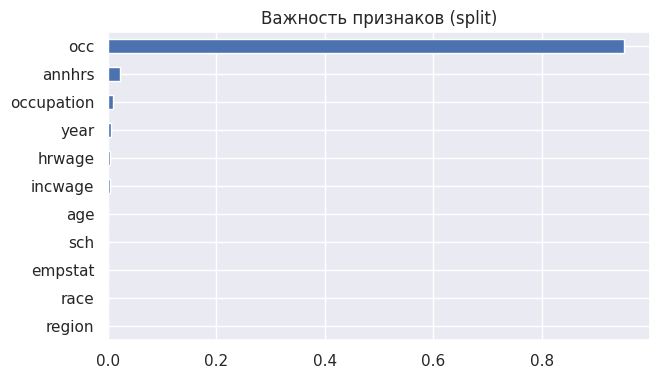

,0
occ,0.951
annhrs,0.023
occupation,0.010
year,0.006
hrwage,0.005
incwage,0.004
age,0.001
sch,0.000
empstat,0.000
race,0.000


In [20]:
best_model = Boosting(**common_params, random_state=69, verbose=False)
best_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=True)

split_importance = pd.Series(best_model.get_feature_importance(type="split"), index=X.columns).sort_values()

split_importance.plot.barh(figsize=(7, 4))
plt.title("Важность признаков (split)")
plt.show()

split_importance[::-1].round(3)

### 💠 2.8. Важность бустинга (1 балл)

Но бустинг и дерево это, как говорится, две большие разницы. Дерево ничего не знает про лосс, оно учится по другим соображениям, которые на самом деле не так важны. И как оказывается, это влияние на лосс можно оценить.

> Проблема предыдущего способа в том, что мы не учитываем, насколько сплит реально помогает в решении задачи минимизации функции потерь. Но зная лосс, а точнее градиент, это можно элементарно оценить

Алгоритм будет такой:
1. Возьмём базовый эстимейтор $b_k$ (`sklearn.tree.DecisionTreeRegressor`)
2. Научимся доставать из него [путь](https://scikit-learn.org/stable/auto_examples/tree/plot_unveil_tree_structure.html) для конкретного объекта $x_i$
3. В этом пути для каждого узла $R_j$ вытащим предсказание $b_k(R_j)(x_i)$ (это параметр `value`) и то, по какой фиче был сделан сплит
4. Для каждого предсказания запишем, на сколько уменьшился лосс (проще всего взять антиградиент, но можно взять критерий информативности из 2.4.1)
   
Повторить для всех деревьев, для всех объектов (или осмысленного их сабсэмпла)

Допишите к бустингу:
- `get_feature_importance(self, X: np.ndarray, y: np.ndarray, type="gain")` — атрибут, который возвращает важность признаков, согласно методу выше

Изменилось ли что-то в важности признаков?

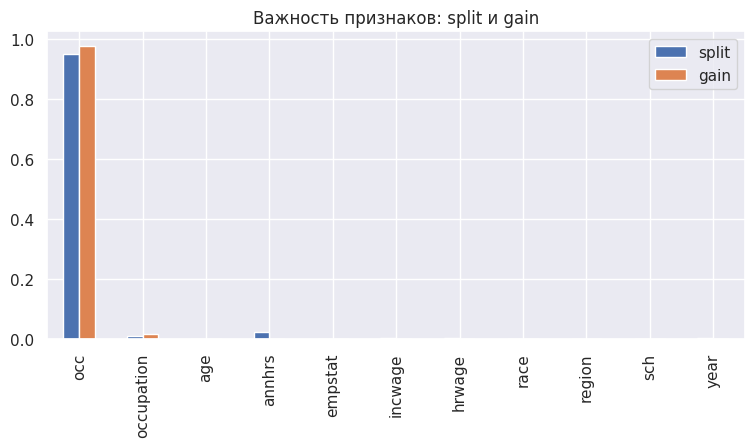

,split,gain
occ,0.951,0.977
occupation,0.010,0.020
age,0.001,0.002
annhrs,0.023,0.002
empstat,0.000,0.000
incwage,0.004,0.000
hrwage,0.005,0.000
race,0.000,0.000
region,0.000,0.000
sch,0.000,0.000


In [21]:
gain_importance = pd.Series(best_model.get_feature_importance(X_valid, y_valid, type="gain"), index=X.columns)

importance_comparison = pd.DataFrame({"split": split_importance, "gain": gain_importance}).sort_values("gain", ascending=False)

importance_comparison.plot.bar(figsize=(9, 4))
plt.title("Важность признаков: split и gain")
plt.show()

importance_comparison.round(3)

**Комментарий к 2.7 и 2.8.** По обоим способам основной вклад вносит `occ`: 0.951 по `split` и 0.977 по `gain`. Различие заметно у `annhrs`: по `split` он получает 0.023, а по `gain` почти ноль (0.002), то же с `hrwage`, `incwage` и `year`. Это значит, что деревья часто делят по этим признакам, но почти ничего не выигрывают в лоссе, то есть это шумные разбиения. `gain` показывает реальный вклад в уменьшение лосса и поэтому надежнее для интерпретации.

### 💠 2.9. DART (1 балл)

Ранее мы обсуждали, что каждый базовый алгоритм пытается исправить ошибки всего предыдущего ансамбля. Из-за этого возникает неравноправие — каждая новая модель вносит все меньший и меньший вклад. Уверенные обучатели нейросетей знают, что это может привести к переобучению, если проводить аналогию с весами. Но выход есть, и выход этот [DART](https://arxiv.org/pdf/1505.01866)!

> В DL есть такой вид регуляризации, как dropout, когда некоторые узлы нейросети со случайным шансом отключаются. Можно попробовать обобщить этот подход на случай бустингов и случайно выкидывать деревья из композиции во время обучения

1. Выбираем, какие деревья убрать. При подсчете антиградиента берем не весь ансамбль, а только ту часть, что осталась
2. Домножаем выходы дерева на $1/k$, где $k$ — число удаленных деревьев, чтобы учесть тот факт, что ансамбль был не весь. Тогда вклад отдельного дерева будет не настолько большим
3. Домножаем выходы выкинутых деревьев на $k/(k+1)$, чтобы масштабы выходов примерно совпадали

Параметры, которые нужно добавить:

- `dart: bool = False` — DART бустинг или нет
- `dropout_rate: float = 0.05` — доля деревьев, которую выкидываем во время обучения DART

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>XGBClassifier(booster="dart")</code></td>
<td align="center"><code>LGBMClassifier(boosting_type="dart")</code></td>
<td align="center"><code>-</code></td>
</tr>
</table>

</div>

Попробуйте обучить DART на наших данных. Статью читать настоятельно рекомендуется, метод не самый простой

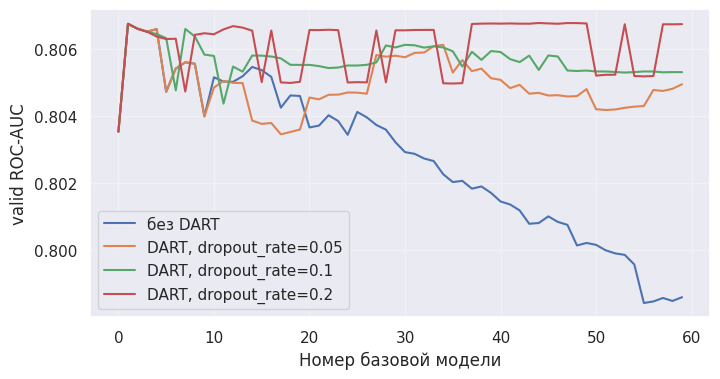

,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,без DART,60,0.8777,0.7986,0.7900,57.8687
1,"DART, dropout_rate=0.05",60,0.8754,0.8050,0.7988,57.2979
2,"DART, dropout_rate=0.1",60,0.8739,0.8053,0.7992,57.9398
3,"DART, dropout_rate=0.2",60,0.8716,0.8067,0.8005,61.8785


In [22]:
dart_configs = {
    "без DART": dict(dart=False),
    "DART, dropout_rate=0.05": dict(dart=True, dropout_rate=0.05),
    "DART, dropout_rate=0.1": dict(dart=True, dropout_rate=0.1),
    "DART, dropout_rate=0.2": dict(dart=True, dropout_rate=0.2),
}

dart_common = dict(base_model_params=dict(max_depth=5), n_estimators=60, learning_rate=0.1, cat_features=[occupation_idx, occ_idx])

plt.figure(figsize=(8, 4))
for name, params in dart_configs.items():
    model = Boosting(random_state=69, verbose=False, **dart_common, **params)
    model.fit(X_train, y_train, eval_set=(X_valid, y_valid))
    plt.plot(model.history["valid_roc_auc"], label=name)
plt.xlabel("Номер базовой модели")
plt.ylabel("valid ROC-AUC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

compare(dart_configs, use_best_model=False, **dart_common)

**Комментарий к DART.** DART заметно помогает против переобучения: при 60 моделях valid ROC-AUC без DART 0.7986, а с DART 0.8050 (`dropout_rate=0.05`), 0.8053 (0.1) и 0.8067 (0.2). Случайное выбрасывание деревьев мешает поздним деревьям просто доучивать ошибки предыдущих. Ранняя остановка с DART несовместима, потому что веса старых деревьев меняются со временем. Вес нового дерева у меня равен `1/(k+1)`, а выброшенных деревьев `k/(k+1)`, как в статье про DART (в тексте задания написано `1/k`, но с `1/(k+1)` масштаб выхода ансамбля сохраняется).

### 💠 2.10. Бустинг линейных моделей (0.5 балла)

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что произойдет при ансамблировании линейных моделей? Имеет ли это смысл?

**Ответ:** сумма линейных функций остается линейной функцией, поэтому ансамбль линейных моделей по выразительности не лучше одной линейной модели, а бустинг превращается в способ оптимизации (по сути градиентный спуск для логистической регрессии с подбором шага). Смысл в нем есть разве что как в способе итерационной регуляризации: ограничение числа шагов и ранняя остановка могут сдерживать переобучение. Это не то же самое, что L2-регуляризация. Для улучшения качества такой бустинг не нужен, он только медленнее, чем обычное обучение линейной модели.

</div>

Давайте убедимся. Обучите бустинг, где в качестве базовой модели будет линейная регрессия. Обязательно сохраните историю функции потерь и зафиксируйте время обучения. Можно взять уже готовый из <font color='#2f82d4'>**XGBoost**</font>, но будьте готовы разобраться с тем, как оттуда достать историю обучения

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>XGBClassifier(booster="gblinear")</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
</tr>
</table>

</div>

In [23]:
from sklearn.linear_model import LinearRegression, SGDClassifier
from sklearn.metrics import log_loss
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train[:, numeric_idx].astype(float))
X_train_lin = scaler.transform(X_train[:, numeric_idx].astype(float))
X_valid_lin = scaler.transform(X_valid[:, numeric_idx].astype(float))
X_test_lin = scaler.transform(X_test[:, numeric_idx].astype(float))

start = time.time()
linear_boosting = Boosting(base_model_class=LinearRegression, n_estimators=100, learning_rate=0.1, random_state=69, verbose=False)
linear_boosting.fit(X_train_lin, y_train, eval_set=(X_valid_lin, y_valid))
linear_boosting_time = time.time() - start

print(f"Бустинг линейных моделей: {linear_boosting_time:.1f} с, "
      f"train loss {linear_boosting.history['train_loss'][-1]:.4f}, valid loss {linear_boosting.history['valid_loss'][-1]:.4f}, "
      f"valid ROC-AUC {linear_boosting.score(X_valid_lin, y_valid):.4f}")

Бустинг линейных моделей: 54.6 с, train loss 0.6848, valid loss 0.6797, valid ROC-AUC 0.5870


Теперь возьмите `sklearn.linear_model.SGDClassifier` и обучите на тех же данных. Не забудьте понять, как вытащить оттуда историю функции потерь

In [24]:
sgd = SGDClassifier(loss="log_loss", penalty=None, learning_rate="constant", eta0=0.01, random_state=69)
sgd_history = {"train_loss": [], "valid_loss": []}

sgd_time = 0.0
for epoch in range(100):
    start = time.time()
    sgd.partial_fit(X_train_lin, y_train, classes=np.array([-1, 1]))
    sgd_time += time.time() - start
    sgd_history["train_loss"].append(log_loss(y_train, sgd.predict_proba(X_train_lin)))
    sgd_history["valid_loss"].append(log_loss(y_valid, sgd.predict_proba(X_valid_lin)))

print(f"SGDClassifier: {sgd_time:.1f} с (только обучение), "
      f"train loss {sgd_history['train_loss'][-1]:.4f}, valid loss {sgd_history['valid_loss'][-1]:.4f}, "
      f"valid ROC-AUC {roc_auc_score(y_valid == 1, sgd.predict_proba(X_valid_lin)[:, 1]):.4f}")

SGDClassifier: 12.3 с (только обучение), train loss 0.6582, valid loss 5.9637, valid ROC-AUC 0.5263


Покажите на одном графике изменение функции потерь для бустинга и SGD классификатора. Сравните следующие детали у бустинга и линейной модели:

- время обучения
- сходимость (как быстро, как стабильно и прочее)
- графики функции потерь на трейне и на валидации

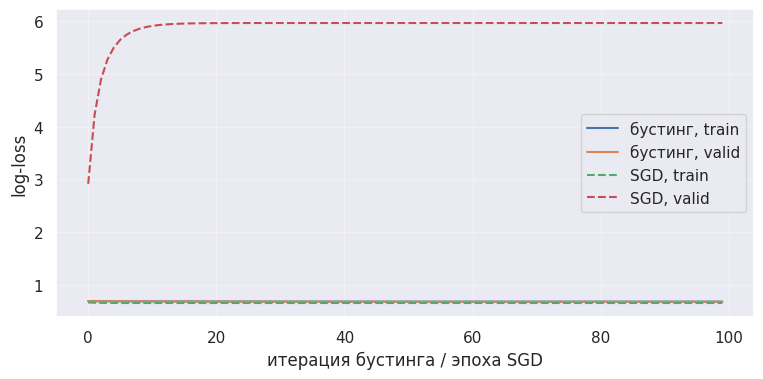

,"время обучения, с",итераций,train loss,valid loss
бустинг линейных моделей,54.6113,100,0.6848,0.6797
SGDClassifier,12.2903,100,0.6582,5.9637


In [25]:
plt.figure(figsize=(9, 4))
plt.plot(linear_boosting.history["train_loss"], label="бустинг, train")
plt.plot(linear_boosting.history["valid_loss"], label="бустинг, valid")
plt.plot(sgd_history["train_loss"], "--", label="SGD, train")
plt.plot(sgd_history["valid_loss"], "--", label="SGD, valid")
plt.xlabel("итерация бустинга / эпоха SGD")
plt.ylabel("log-loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

pd.DataFrame({
    "время обучения, с": [linear_boosting_time, sgd_time],
    "итераций": [len(linear_boosting.history["train_loss"]), len(sgd_history["train_loss"])],
    "train loss": [linear_boosting.history["train_loss"][-1], sgd_history["train_loss"][-1]],
    "valid loss": [linear_boosting.history["valid_loss"][-1], sgd_history["valid_loss"][-1]],
}, index=["бустинг линейных моделей", "SGDClassifier"]).round(4)

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Какой вывод вы можете сделать?

**Ответ:** бустинг линейных моделей обучался 54.6 с (в это время входит подсчет истории метрик на каждой итерации), `SGDClassifier` 12.3 с чистого обучения. Бустинг: train loss 0.6848, valid loss 0.6797, valid ROC-AUC 0.587. SGD: train loss 0.6582 (он ушел дальше по обучающей выборке), но valid loss 5.96 и ROC-AUC 0.526.

Плохой valid у SGD объясняется не шагом обучения, а сдвигом данных. В 2011 году среднее `annhrs` равно примерно 293 против примерно 18 в обучающей выборке (аналогично `hrwage` и `incwage`). После стандартизации по train эти значения становятся огромными, и линейная модель выдает гигантские логиты. Если убрать три этих столбца, SGD дает valid loss 0.6805 и ROC-AUC 0.5855, то есть то же, что и бустинг. Бустинг за 100 шагов со скоростью 0.1 ушел от нуля недалеко, поэтому он менее чувствителен к этому сдвигу, но это скорее побочный эффект недообучения.

Итог: оба варианта слабы (ROC-AUC 0.52-0.59), потому что линейная модель на числовых признаках без категорий почти ничего не объясняет. Бустинг линейных моделей решает ту же задачу, что и обычное обучение логистической регрессии, но медленнее, а значит, смысла в нем нет.

</div>

### 💠 2.11. Потери потерь (0.5 балла)

Если вы смотрели в датасет, то вероятно заметили, что данные в нём несбалансированы. С этим можно жить, и этому вы научитесь на мо2, но нужно ли? Ведь всегда можно шлёпнуть простой советский проверенный способ, который в бустингах применяется не слишком широко, по непонятной, честно говоря, причине.

Смотрите, какая существует штука:

$$
\text{FocalLoss}(y, z) = -\frac{1}{n}\sum_{i=1}^{n} \left(1 - \sigma(y_i z_i)\right)^{\gamma} \log\!\big(\sigma(y_i z_i)\big)
$$

Что же это за покемон?
- параметр $\gamma$ (это другой гамма, свой, не бустинговый) регулирует, как сильно я акцентирую внимание на тех объектах, которых много, и которые легко разметить. Чем он больше, тем больше игнорим лёгкие примеры
- вес $(1 - \sigma(y_i z_i))$ регулирует вклад в лосс, в зависимости от класса
- в остальном это тот же логлосс

>Если разметить объект легко, то есть сигмоида даёт результат, близкий к единице, то нам как бы максимально всё равно, какой у него вклад в лосс, множитель под гаммой будет примерно 0, интереснее же на сложных примерах обучаться. А если сложно, то вклад напротив максимальный, объект полностью участвует в расчёте лосса

Хочется увидеть в классе `Boosting`:
- `loss: str = 'BCE` — лосс, на который обучаем бустинг, по дефолту `'BCE'` - бинарная кросс-энтропия, aka логистическая функция потерь
- `focal_gamma: float = 2.0` — гиперпараметр для силы фокал лосса, чем-то похож на `class_weights`, но поинтереснее
- методы `loss_fn` и `grad_fn` для фокал лосса

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>objective="custom"</code></td>
<td align="center"><code>objective="custom"</code></td>
<td align="center"><code>loss_function="FocalLoss"</code></td>
</tr>
</table>

</div>

Получилось? Покажите. Должно было стать чуть получше

In [26]:
print(pd.Series(y_train).value_counts(normalize=True).round(3))

focal_configs = {"BCE": dict(loss="BCE")}
for focal_gamma in [1.0, 2.0, 5.0]:
    focal_configs[f"focal, gamma={focal_gamma}"] = dict(loss="focal", focal_gamma=focal_gamma)

compare(focal_configs, **common_params)

 1    0.514
-1    0.486
Name: proportion, dtype: float64


,конфигурация,моделей,train ROC-AUC,valid ROC-AUC,test ROC-AUC,"время, с"
0,BCE,2,0.8700,0.8068,0.8008,15.1973
1,"focal, gamma=1.0",5,0.8723,0.8076,0.8015,19.7946
2,"focal, gamma=2.0",5,0.8724,0.8075,0.8015,19.1416
3,"focal, gamma=5.0",3,0.8702,0.8067,0.8005,20.6810


**Комментарий к фокал-лоссу.** Сильного улучшения нет: valid ROC-AUC 0.8076 (gamma=1) и 0.8075 (gamma=2) против 0.8068 у BCE. Причина скорее всего в том, что классы почти сбалансированы (51.4% и 48.6%), а фокал-лосс нужен для сильно несбалансированных выборок.

------

## Задание 3. Около бустинга (📌 1 балл |💠 1.25 балла)

Теперь давайте проанализируем, как же правильно готовить бустинги. Нас интересует: как тюнить бустинги, какие они вообще бывают и как их интерпретировать. Посмотрим на все это по порядку

### 📌 3.1. Optuna наносит ответный удар (0.5 балла)

Если вы помните, у нас уже было знакомство с библиотекой `optuna` для подбора гиперпараметров. Вспомним, как это делается и подумаем, как это можно делать еще лучше

Подберите на валидации оптимальные значения следующих гиперпараметров для вашей реализации бустинга:
- `max_depth`
- `n_estimators`
- `learning_rate`
- любые другие, которые вы сделали в части 2

Подберите диапазон параметров самостоятельно, не забывайте фиксировать сид (нет, его не нужно перебирать). Сохраните и покажите оптимальный набор параметров. Покажите, какие из них дали наибольший прирост.

In [28]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [29]:
import optuna

cat_sets = {
    "occupation": [X.columns.get_loc("occupation")],
    "occupation + occ": [X.columns.get_loc("occupation"), X.columns.get_loc("occ")],
}


def objective(trial, model="custom_boosting"):

    boosting_params = dict(
        n_estimators=trial.suggest_int("n_estimators", 30, 150, step=10),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
    )

    tree_params = dict(
        max_depth=trial.suggest_int("max_depth", 2, 7),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 200, log=True),
    )

    conditional_params = {}
    if trial.suggest_categorical("use_early_stopping", [True, False]):
        conditional_params["early_stopping_rounds"] = trial.suggest_int("early_stopping_rounds", 5, 30)

    cat_features = cat_sets[trial.suggest_categorical("cat_set", list(cat_sets))]

    boosting = Boosting(
        base_model_params=tree_params,
        cat_features=cat_features,
        eval_metric="valid_roc_auc",
        random_state=69,
        verbose=False,
        **boosting_params,
        **conditional_params,
    )
    boosting.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=bool(conditional_params))
    return boosting.score(X_valid, y_valid)

[I 2026-11-23 18:02:57,926] A new study created in memory with name: no-name-04d6d367-447b-4311-a265-ce8e801f3790
[I 2026-11-23 18:03:10,346] Trial 0 finished with value: 0.8153871775629546 and parameters: {'n_estimators': 60, 'learning_rate': 0.1788823386426276, 'max_depth': 4, 'min_samples_leaf': 57, 'use_early_stopping': True, 'early_stopping_rounds': 7, 'cat_set': 'occupation + occ'}. Best is trial 0 with value: 0.8153871775629546.
[I 2026-11-23 18:05:10,796] Trial 1 finished with value: 0.7929558958467873 and parameters: {'n_estimators': 120, 'learning_rate': 0.14549561981522535, 'max_depth': 6, 'min_samples_leaf': 1, 'use_early_stopping': False, 'cat_set': 'occupation + occ'}. Best is trial 0 with value: 0.8153871775629546.
[I 2026-11-23 18:05:51,805] Trial 2 finished with value: 0.8142269660062804 and parameters: {'n_estimators': 50, 'learning_rate': 0.04802868487273741, 'max_depth': 4, 'min_samples_leaf': 12, 'use_early_stopping': True, 'early_stopping_rounds': 22, 'cat_set': '

Лучший valid ROC-AUC: 0.8174
Лучшие параметры: {'n_estimators': 150, 'learning_rate': 0.07219392886087363, 'max_depth': 2, 'min_samples_leaf': 2, 'use_early_stopping': True, 'early_stopping_rounds': 30, 'cat_set': 'occupation + occ'}


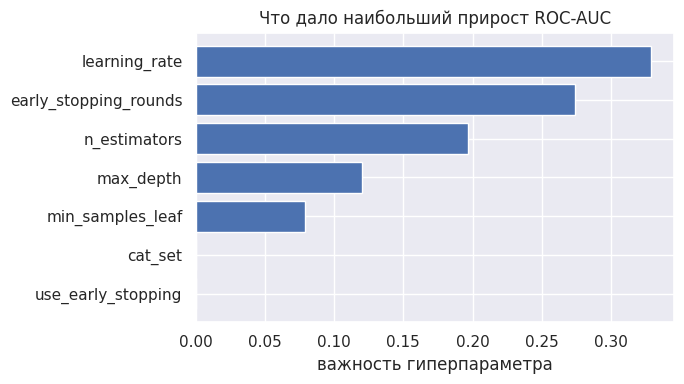

Valid ROC-AUC 0.8174
Test ROC-AUC 0.8116


In [30]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=69))
study.optimize(objective, n_trials=25)

print(f"Лучший valid ROC-AUC: {study.best_value:.4f}")
print("Лучшие параметры:", study.best_params)

importances = optuna.importance.get_param_importances(study)
plt.figure(figsize=(7, 4))
plt.barh(list(importances)[::-1], list(importances.values())[::-1])
plt.xlabel("важность гиперпараметра")
plt.title("Что дало наибольший прирост ROC-AUC")
plt.tight_layout()
plt.show()

best = study.best_params
final = Boosting(
    n_estimators=best["n_estimators"],
    learning_rate=best["learning_rate"],
    base_model_params=dict(max_depth=best["max_depth"], min_samples_leaf=best["min_samples_leaf"]),
    early_stopping_rounds=best.get("early_stopping_rounds", 0),
    eval_metric="valid_roc_auc",
    cat_features=cat_sets[best["cat_set"]],
    random_state=69,
    verbose=False,
)
final.fit(X_train, y_train, eval_set=(X_valid, y_valid), use_best_model=final.early_stopping_rounds > 0)
print(f"Valid ROC-AUC {final.score(X_valid, y_valid):.4f}")
print(f"Test ROC-AUC {final.score(X_test, y_test):.4f}")

Выбейте ROC-AUC хотя бы 0.8, и можете двигаться дальше

### 📌 3.2. Готовые реализации (0.5 балла)

Библиотек для бустингов существует много, но активно используются лишь три. Вам предстоит попробовать их в деле, посмотреть на их уникальные фишки и понять, что вам нравится больше всего

Возьмите любую из популярных библиотек: <font color='#2f82d4'>**XGBoost**</font>, <font color='#53c96c'>**LightGBM**</font> или <font color='#c4bf0a'>**CatBoost**</font>.
Ваша задача — взять одну из них, подобрать те же оптимальные параметры, что и выше, а также вставить [прунер](https://optuna.readthedocs.io/en/stable/reference/pruners.html).

Идея прунера — не обучать бустинг до конца, если по истории валидации видно, что другие бустинги на этом этапе статистически лучше, для этого мы и делали `partial_fit`, но в готовые реализации его можно вставить при помощи CallBack, для этого придётся немножко погуглить. Это во-первых, заметно ускоряет процесс перебора гиперпарамтеров, во-вторых неявно регуляризует модельку

Цель — увидеть в логах оптуны `Trial.PRUNED`, это знак того, что прунер работает. Если вы этого не видите, вероятно, вы вставили его неправильно.

In [31]:
import lightgbm as lgb
from collections import Counter

X_lgb = X.copy()
train_mask = (X["year"] < 2011).values
for column in ["occupation", "occ"]:
    categories = sorted(X_lgb.loc[train_mask, column].unique())
    X_lgb[column] = X_lgb[column].astype(pd.CategoricalDtype(categories))

X_train_lgb = X_lgb[X["year"] < 2011]
X_valid_lgb = X_lgb[X["year"] == 2011]
X_test_lgb = X_lgb[X["year"] == 2013]


def pruning_callback(trial):
    def callback(env):
        score = next(value for _, name, value, _ in env.evaluation_result_list if name == "auc")
        trial.report(score, step=env.iteration)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return callback


def objective_lgbm(trial):
    max_depth = trial.suggest_int("max_depth", 2, 7)
    callbacks = [pruning_callback(trial)]
    if trial.suggest_categorical("use_early_stopping", [True, False]):
        callbacks.append(lgb.early_stopping(trial.suggest_int("early_stopping_rounds", 5, 30), verbose=False))

    model = lgb.LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 30, 300, step=10),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        max_depth=max_depth,
        num_leaves=2 ** max_depth,
        min_child_samples=trial.suggest_int("min_child_samples", 1, 200, log=True),
        metric="auc",
        random_state=69,
        verbose=-1,
    )
    model.fit(X_train_lgb, y_train, eval_set=[(X_valid_lgb, y_valid)], callbacks=callbacks)
    return roc_auc_score(y_valid == 1, model.predict_proba(X_valid_lgb)[:, 1])


study_lgb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=69),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=10),
)
study_lgb.optimize(objective_lgbm, n_trials=40)

print(Counter(trial.state.name for trial in study_lgb.trials))
print(f"Лучший valid ROC-AUC: {study_lgb.best_value:.4f}")
print("Лучшие параметры:", study_lgb.best_params)


[I 2026-11-23 18:33:20,386] A new study created in memory with name: no-name-6fa31b08-a9dd-40d4-b391-60af748f8284
[I 2026-11-23 18:33:22,388] Trial 0 finished with value: 0.8324489638516659 and parameters: {'max_depth': 3, 'use_early_stopping': True, 'early_stopping_rounds': 25, 'n_estimators': 180, 'learning_rate': 0.03974419894767895, 'min_child_samples': 1}. Best is trial 0 with value: 0.8324489638516659.
[I 2026-11-23 18:33:27,984] Trial 1 finished with value: 0.7997093138221081 and parameters: {'max_depth': 2, 'use_early_stopping': False, 'n_estimators': 230, 'learning_rate': 0.16890472120914582, 'min_child_samples': 1}. Best is trial 0 with value: 0.8324489638516659.
[I 2026-11-23 18:33:30,380] Trial 2 finished with value: 0.8327816333243825 and parameters: {'max_depth': 3, 'use_early_stopping': True, 'early_stopping_rounds': 17, 'n_estimators': 80, 'learning_rate': 0.04802868487273741, 'min_child_samples': 8}. Best is trial 2 with value: 0.8327816333243825.
[I 2026-11-23 18:33:3

Counter({'COMPLETE': 27, 'PRUNED': 13})
Лучший valid ROC-AUC: 0.8345
Лучшие параметры: {'max_depth': 4, 'use_early_stopping': True, 'early_stopping_rounds': 12, 'n_estimators': 30, 'learning_rate': 0.1430602652920679, 'min_child_samples': 2}


<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Какая архитектура вам нравится больше всего и почему?

**Ответ:** мне больше всего понравился LightGBM. В моих запусках он оказался самым быстрым (40 испытаний Optuna с прунером заняли меньше времени, чем несколько испытаний на моей реализации), лучше всех на этих данных (valid ROC-AUC 0.8345), нативно принимает категории через pandas-тип `category` и без лишнего кода подключается к прунеру через callback. XGBoost работает похоже, но у него пришлось явно включать `enable_categorical`. CatBoost лучше всех по идее обращается с категориями (упорядоченные счетчики), но обучается дольше и сложнее встраивается в подбор гиперпараметров.

</div>

### 💠 3.3. <font color='#2f82d4'>**XGBoost**</font> и велосипеды (0.25 баллов)

<font color='#2f82d4'>**XGBoost**</font> известен тем, что в нем впервые повилась регуляризация. Ручками ее написать сложно, и вы даже могли попробовать пунктом ранее, но зачем? Она уже написана, вообще-то. Вместо того, чтобы заниматься ерундой, можем попробовать импортировать и посмотреть, насколько она полезна в лучшем своём представлении.

Добавьте оба вида регуляризации, что там есть, как параметры в оптуну, и прогоните процесс оптимизации только на них.

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>alpha</code>, <code>lambda</code></td>
<td align="center"><code>lambda_l1</code>, <code>lambda_l2</code></td>
<td align="center"><code>-</code>, <code>l2_leaf_reg</code></td>
</tr>
</table>

</div>

In [32]:
import xgboost as xgb

best_lgb = study_lgb.best_params
fixed_xgb = dict(
    n_estimators=best_lgb["n_estimators"], learning_rate=best_lgb["learning_rate"], max_depth=best_lgb["max_depth"],
    tree_method="hist", enable_categorical=True, random_state=69,
)


def fit_xgb(reg_alpha, reg_lambda):
    model = xgb.XGBClassifier(reg_alpha=reg_alpha, reg_lambda=reg_lambda, **fixed_xgb)
    return model.fit(X_train_lgb, (y_train == 1).astype(int))


def xgb_auc(model, features, target):
    return roc_auc_score(target == 1, model.predict_proba(features)[:, 1])


def objective_reg(trial):
    model = fit_xgb(
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 50, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 200, log=True),
    )
    return xgb_auc(model, X_valid_lgb, y_valid)


study_reg = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=69))
study_reg.optimize(objective_reg, n_trials=40)

reg_rows = []
for name, (alpha, lam) in {
    "без регуляризации (alpha=0, lambda=0)": (0.0, 0.0),
    "по умолчанию XGBoost (alpha=0, lambda=1)": (0.0, 1.0),
    f"Optuna (alpha={study_reg.best_params['reg_alpha']:.3g}, lambda={study_reg.best_params['reg_lambda']:.3g})":
        (study_reg.best_params["reg_alpha"], study_reg.best_params["reg_lambda"]),
}.items():
    model = fit_xgb(alpha, lam)
    reg_rows.append({
        "регуляризация": name,
        "train ROC-AUC": xgb_auc(model, X_train_lgb, y_train),
        "valid ROC-AUC": xgb_auc(model, X_valid_lgb, y_valid),
        "test ROC-AUC": xgb_auc(model, X_test_lgb, y_test),
    })

pd.DataFrame(reg_rows).round(4)

[I 2026-11-23 18:34:26,138] A new study created in memory with name: no-name-e035d43b-be8e-4f83-bfb5-b977594e6904
[I 2026-11-23 18:34:27,513] Trial 0 finished with value: 0.8093483688025629 and parameters: {'reg_alpha': 0.024664137025038245, 'reg_lambda': 19.44877398095766}. Best is trial 0 with value: 0.8093483688025629.
[I 2026-11-23 18:34:28,834] Trial 1 finished with value: 0.8095305941937408 and parameters: {'reg_alpha': 0.04424111969574555, 'reg_lambda': 15.299672945629885}. Best is trial 1 with value: 0.8095305941937408.
[I 2026-11-23 18:34:30,148] Trial 2 finished with value: 0.8096112458518571 and parameters: {'reg_alpha': 0.4342721702865246, 'reg_lambda': 0.022094422416238876}. Best is trial 2 with value: 0.8096112458518571.
[I 2026-11-23 18:34:31,446] Trial 3 finished with value: 0.8065114373508653 and parameters: {'reg_alpha': 0.0031137530602654085, 'reg_lambda': 0.0020412776431728012}. Best is trial 2 with value: 0.8096112458518571.
[I 2026-11-23 18:34:32,896] Trial 4 fini

,регуляризация,train ROC-AUC,valid ROC-AUC,test ROC-AUC
0,"без регуляризации (alpha=0, lambda=0)",0.8840,0.8061,0.8009
1,"по умолчанию XGBoost (alpha=0, lambda=1)",0.8856,0.8125,0.8070
2,"Optuna (alpha=1.45, lambda=6.3)",0.8849,0.8145,0.8082


<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Насколько регуляризация вообще эффективна?

**Ответ:** Регуляризация XGBoost помогает умеренно. Без нее (alpha=0, lambda=0) valid / test ROC-AUC 0.8061 / 0.8009, со значениями по умолчанию (lambda=1) 0.8125 / 0.8070, после подбора Optuna (alpha=1.45, lambda=6/3) 0.8145 / 0.8082. Основной прирост (около 0.6-0.7 п.п.) дает уже lambda=1 по умолчанию, а дальнейший подбор добавляет меньше 0.1 п.п., то есть в пределах шума. Разрыв между train (0.885) и test (0.808) почти не уменьшился, значит, главный источник переобучения здесь не веса в листьях, а сами признаки и сдвиг данных.

</div>

### 💠 3.4. <font color='#53c96c'>**LightGBM**</font>, лес vs бустинг (0.25 балла)

<font color='#53c96c'>**LightGBM**</font> велик по многим причинам. В нём самое большое количество гиперпараметров из всех библиотек. А ещё он содержит в себе реализацию своего злейшего врага — случайный лес, это очень по-философски.

Посмотрите, какие есть параметры у него, обучите так сильно, как только сможете (не забудьте про свойства случайного леса к переобучению, про категориальные энкодеры и прочее).

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>num_parallel_tree</code></td>
<td align="center"><code>boosting_type="rf"</code></td>
<td align="center"><code>-</code></td>
</tr>
</table>

</div>

In [33]:
def objective_rf(trial):
    model = lgb.LGBMClassifier(
        boosting_type="rf",
        n_estimators=trial.suggest_int("n_estimators", 50, 300, step=50),
        num_leaves=trial.suggest_int("num_leaves", 64, 2048, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 1, 100, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 0.9),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        metric="auc",
        random_state=69,
        verbose=-1,
    )
    model.fit(X_train_lgb, y_train)
    return roc_auc_score(y_valid == 1, model.predict_proba(X_valid_lgb)[:, 1])


study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=69))
study_rf.optimize(objective_rf, n_trials=20)

rf = lgb.LGBMClassifier(boosting_type="rf", subsample_freq=1, metric="auc", random_state=69, verbose=-1,
                        **{k: v for k, v in study_rf.best_params.items()})
rf.fit(X_train_lgb, y_train)

gbdt = lgb.LGBMClassifier(
    n_estimators=best_lgb["n_estimators"], learning_rate=best_lgb["learning_rate"],
    max_depth=best_lgb["max_depth"], num_leaves=2 ** best_lgb["max_depth"],
    min_child_samples=best_lgb["min_child_samples"], metric="auc", random_state=69, verbose=-1,
)
gbdt.fit(X_train_lgb, y_train)

rows = []
for name, model in [("случайный лес (LightGBM rf)", rf), ("градиентный бустинг (LightGBM gbdt)", gbdt)]:
    rows.append({
        "модель": name,
        "train ROC-AUC": roc_auc_score(y_train == 1, model.predict_proba(X_train_lgb)[:, 1]),
        "valid ROC-AUC": roc_auc_score(y_valid == 1, model.predict_proba(X_valid_lgb)[:, 1]),
        "test ROC-AUC": roc_auc_score(y_test == 1, model.predict_proba(X_test_lgb)[:, 1]),
    })

print("лучшие параметры леса:", study_rf.best_params)
pd.DataFrame(rows).round(4)

[I 2026-11-23 18:35:34,063] A new study created in memory with name: no-name-d59ee1a7-2625-4a08-932a-382eb4bcabd1
[I 2026-11-23 18:35:45,293] Trial 0 finished with value: 0.7979325509261976 and parameters: {'n_estimators': 100, 'num_leaves': 1055, 'min_child_samples': 3, 'subsample': 0.815763702572357, 'colsample_bytree': 0.7368093854623435}. Best is trial 0 with value: 0.7979325509261976.
[I 2026-11-23 18:35:50,514] Trial 1 finished with value: 0.8061842964414716 and parameters: {'n_estimators': 100, 'num_leaves': 91, 'min_child_samples': 1, 'subsample': 0.7693169523079377, 'colsample_bytree': 0.8186977942010261}. Best is trial 1 with value: 0.8061842964414716.
[I 2026-11-23 18:36:18,280] Trial 2 finished with value: 0.8063694971071245 and parameters: {'n_estimators': 250, 'num_leaves': 980, 'min_child_samples': 1, 'subsample': 0.6270722386479857, 'colsample_bytree': 0.8446139663101762}. Best is trial 2 with value: 0.8063694971071245.
[I 2026-11-23 18:36:25,941] Trial 3 finished with 

лучшие параметры леса: {'n_estimators': 300, 'num_leaves': 1335, 'min_child_samples': 5, 'subsample': 0.7468446910666453, 'colsample_bytree': 0.9185385471127661}


,модель,train ROC-AUC,valid ROC-AUC,test ROC-AUC
0,случайный лес (LightGBM rf),0.9032,0.8099,0.8030
1,градиентный бустинг (LightGBM gbdt),0.8828,0.8121,0.8065


<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Кто победит: бустинг или лес? и почему?

**Ответ:** бустинг оказался лучше леса: LightGBM gbdt даёт valid / test ROC-AUC 0.8121 / 0.8065, лес (`boosting_type="rf"`, 250 деревьев, около 980 листьев, `min_child_samples=1`) 0.8099 / 0.8030. При этом на train лес лучше (0.9032 против 0.8828), то есть он переобучается сильнее. Лес усредняет глубокие независимые деревья и снижает разброс, но не снижает смещение. Бустинг последовательно исправляет ошибки и использует ограниченные по глубине деревья, поэтому он обобщает лучше. Категории я подавала как нативные, а не как счетчики по таргету: у леса переобученные деревья сильнее всего страдают от утечки таргета в счетчик.

</div>

### 💠 3.5. Еще пара красивых слов про <font color='#c4bf0a'>**CatBoost**</font> (0.25 балла)

<font color='#c4bf0a'>**CatBoost**</font> славится ещё и кучей разных подходов к обучению деревьев, в частности он умеет мёрджить несколько моделей в одно. Это не стекинг, и даже не беггинг, а совершенно другой уровень. Поскольку бустинги это уже некоторая сумма деревьев, ничего не мешает брать и складывать уже сами бустинги между собой.

 Попробуйте разбить выборку на фолды и обучить по катбусту на каждом из них, а затем их склеить. Тюнить их не надо, он и так неплох, в этом его сила и мудрость.

<div align="center">

<table>
<tr>
<td align="center"><b><font color="#2f82d4">XGBoost</font></b></td>
<td align="center"><b><font color="#53c96c">LightGBM</font></b></td>
<td align="center"><b><font color="#c4bf0a">CatBoost</font></b></td>
</tr>
<tr>
<td align="center"><code>-</code></td>
<td align="center"><code>-</code></td>
<td align="center"><code>sum_models</code>, <code>to_classifier</code></td>
</tr>
</table>

</div>

Оцените, насколько это круто по 10-балльной

In [35]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 42.9 MB/s  0:00:02


In [36]:
from catboost import CatBoostClassifier, sum_models, to_classifier
from sklearn.model_selection import KFold

X_cb_train = X[X["year"] < 2011]
X_cb_valid = X[X["year"] == 2011]
X_cb_test = X[X["year"] == 2013]
target_train = (y_train == 1).astype(int)

fold_models = []
for fold_train_idx, _ in KFold(n_splits=5, shuffle=True, random_state=69).split(X_cb_train):
    model = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, cat_features=["occupation", "occ"],
                               random_seed=69, verbose=0)
    model.fit(X_cb_train.iloc[fold_train_idx], target_train[fold_train_idx])
    fold_models.append(model)

merged = to_classifier(sum_models(fold_models, weights=[1 / len(fold_models)] * len(fold_models)))


def cb_auc(model, features, target):
    return roc_auc_score(target == 1, model.predict_proba(features)[:, 1])


rows = [{
    "модель": f"фолд {i + 1}",
    "valid ROC-AUC": cb_auc(model, X_cb_valid, y_valid),
    "test ROC-AUC": cb_auc(model, X_cb_test, y_test),
} for i, model in enumerate(fold_models)]
rows.append({
    "модель": "склеенная (sum_models)",
    "valid ROC-AUC": cb_auc(merged, X_cb_valid, y_valid),
    "test ROC-AUC": cb_auc(merged, X_cb_test, y_test),
})

pd.DataFrame(rows).round(4)

,модель,valid ROC-AUC,test ROC-AUC
0,фолд 1,0.8268,0.8232
1,фолд 2,0.8197,0.8140
2,фолд 3,0.8205,0.8141
3,фолд 4,0.8154,0.7960
4,фолд 5,0.8193,0.8029
5,склеенная (sum_models),0.8250,0.8172


Пусть будет **7/10.** Склеенная модель (`sum_models` по 5 фолдам) получила valid / test ROC-AUC 0.825 / 0.8172. Отдельные модели на фолдах дают 0.815-0.823 по valid (среднее около 0.82), одна модель на всех данных 0.8182 / 0.8078. То есть склейка лучше и среднего по фолдам, и единой модели, как и должно быть. Но это дешевый способ получить ансамбль (обучить нужно k моделей), выразительность модели он не повышает, и результат зависит от разбиения. Поэтому 7, а не выше :)

### 💠 3.6. Бустинг и вероятности (0.5 балла)

С качеством мы более-менее разобрались, но таки что насчет вероятностей? Постройте калибровочную кривую для вашей лучшей модели бустинга. Насколько хорошо бустинг оценивает вероятности?

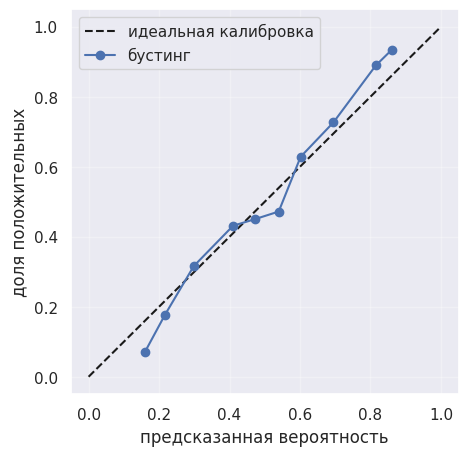

In [37]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss, log_loss

proba_boosting = final.predict_proba(X_test)[:, 1]
fraction_positive, mean_predicted = calibration_curve(y_test == 1, proba_boosting, n_bins=10, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="идеальная калибровка")
plt.plot(mean_predicted, fraction_positive, "o-", label="бустинг")
plt.xlabel("предсказанная вероятность")
plt.ylabel("доля положительных")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Постройте также калибровочную кривую для логистической регрессии, сравните их между собой. Проанализируйте полученные результаты.

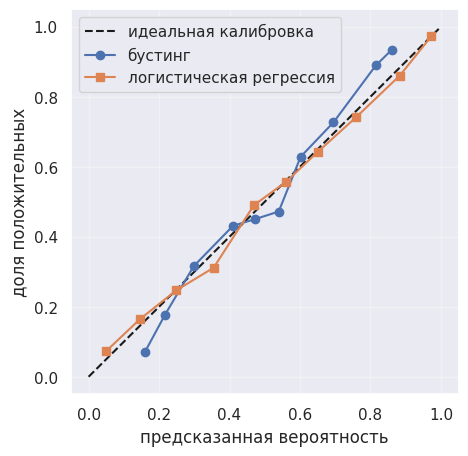

,LogLoss,Brier,ROC-AUC
бустинг,0.5358,0.1793,0.8116
логистическая регрессия,0.5001,0.1665,0.8333


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

logreg = make_pipeline(
    ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), ["region", "race", "empstat", "occ", "occupation"]),
        ("numbers", StandardScaler(), ["age", "sch"]),
    ]),
    LogisticRegression(max_iter=1000),
)
logreg.fit(X[X["year"] < 2011], y_train == 1)

proba_logreg = logreg.predict_proba(X[X["year"] == 2013])[:, 1]
fraction_positive_lr, mean_predicted_lr = calibration_curve(y_test == 1, proba_logreg, n_bins=10, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="идеальная калибровка")
plt.plot(mean_predicted, fraction_positive, "o-", label="бустинг")
plt.plot(mean_predicted_lr, fraction_positive_lr, "s-", label="логистическая регрессия")
plt.xlabel("предсказанная вероятность")
plt.ylabel("доля положительных")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

pd.DataFrame({
    "LogLoss": [log_loss(y_test == 1, proba_boosting), log_loss(y_test == 1, proba_logreg)],
    "Brier": [brier_score_loss(y_test == 1, proba_boosting), brier_score_loss(y_test == 1, proba_logreg)],
    "ROC-AUC": [roc_auc_score(y_test == 1, proba_boosting), roc_auc_score(y_test == 1, proba_logreg)],
}, index=["бустинг", "логистическая регрессия"]).round(4)

Конечно же, бустинг великолепен, как он есть, но можно сделать его еще лучше, если его откалибровать

1. Посмотрите на то, как это делать из библиотеки `sklearn`. Обратите внимание, передаете вы в него обученную модель или нет, а также на чем вы калибруетесь. Иначе есть риск что-то поломать
2. Откалибруйте вашу реализацию бустинга. Для этого за вас к нему был замешан `ClassifierMixin`
3. Покажите, как изменилась мера откалиброванности, для этого есть
$$\text{LogLoss} = -\frac{1}{N}\sum_{i} \sum_{k \in {0. 1}}\log p_k[y_i = k]; \qquad \text{BrierScore} = \frac{1}{N}\sum_{i} (p_i - y_i)^2;$$
4. Нарисуйте новую калибровочную кривую

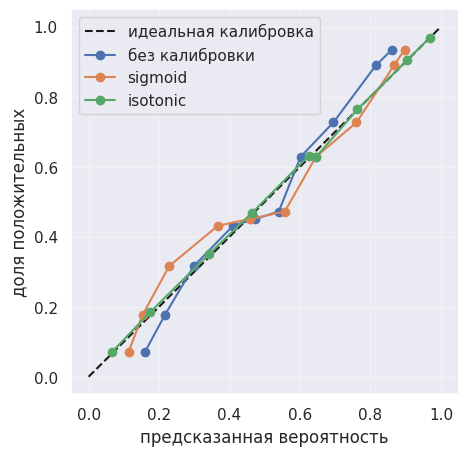

,модель,LogLoss,Brier
0,бустинг без калибровки,0.5358,0.1793
1,бустинг + sigmoid,0.5325,0.1790
2,бустинг + isotonic,0.5191,0.1741


In [39]:
rows = [{
    "модель": "бустинг без калибровки",
    "LogLoss": log_loss(y_test == 1, proba_boosting),
    "Brier": brier_score_loss(y_test == 1, proba_boosting),
}]
calibrated_proba = {}
for method in ["sigmoid", "isotonic"]:
    calibrated = CalibratedClassifierCV(FrozenEstimator(final), method=method)
    calibrated.fit(X_valid, y_valid)
    calibrated_proba[method] = calibrated.predict_proba(X_test)[:, 1]
    rows.append({
        "модель": f"бустинг + {method}",
        "LogLoss": log_loss(y_test == 1, calibrated_proba[method]),
        "Brier": brier_score_loss(y_test == 1, calibrated_proba[method]),
    })

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="идеальная калибровка")
for name, proba in [("без калибровки", proba_boosting), ("sigmoid", calibrated_proba["sigmoid"]), ("isotonic", calibrated_proba["isotonic"])]:
    fraction, mean_pred = calibration_curve(y_test == 1, proba, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, fraction, "o-", label=name)
plt.xlabel("предсказанная вероятность")
plt.ylabel("доля положительных")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

pd.DataFrame(rows).round(4)

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** Как вы можете прокомментировать то, что получилось?

**Ответ:** Бустинг неплохо разделяет объекты по классам, но с оценкой вероятностей у него есть проблемы. Это видно по калибровочной кривой: предсказанные вероятности распределены в довольно узком диапазоне, а фактические доли положительных объектов в группах заметно отличаются от них. Получается, что модель недостаточно хорошо оценивает вероятность принадлежности к классу. Это также отражается на метриках: LogLoss = 0.5358, Brier = 0.1793, хотя ROC-AUC составляет 0.8116.

Для сравнения я обучила логистическую регрессию. В качестве категориальных признаков использовала `region`, `race`, `empstat`, `occ` и `occupation`, а `age` и `sch` масштабировала с помощью `StandardScaler`. Ее калибровочная кривая оказалась ближе к диагонали, то есть предсказанные вероятности лучше соответствуют фактическим долям положительного класса. Кроме того, логистическая регрессия показала лучшие результаты по всем трем метрикам: LogLoss = 0.5001, Brier = 0.1665, ROC-AUC = 0.8333.

На этом примере хорошо видно, что высокий ROC-AUC еще не гарантирует хорошую калибровку вероятностей. Эта метрика оценивает качество ранжирования объектов, но не показывает, насколько точно предсказанная вероятность соответствует реальной.

Дальше я попробовала откалибровать сам бустинг с помощью `CalibratedClassifierCV`. Для этого использовала два метода: `sigmoid` и `isotonic`. Калибратор обучался на отложенной валидационной выборке, а итоговые метрики я считала на тестовой.

Оба метода немного улучшили результат. Для `sigmoid` LogLoss составил 0.5325, а Brier - 0.1790. Для `isotonic` результаты оказались лучше: 0.5191 и 0.1741 соответственно. Таким образом, в моем эксперименте лучше сработала изотоническая регрессия. Она не предполагает заранее определенную форму зависимости между исходными оценками модели и вероятностями, а подбирает монотонное преобразование по данным.

В `CalibratedClassifierCV` я использовала `FrozenEstimator(final)`, чтобы зафиксировать уже обученный бустинг и обучать только калибратор. Это важно, поскольку для калибровки нужны данные, которые не использовались при обучении исходной модели. В моем случае для этого подходит валидационная выборка.

В итоге изотоническая калибровка заметно улучшила качество вероятностных предсказаний бустинга, хотя полностью проблему не решила. Интересно, что простая логистическая регрессия без дополнительной калибровки все равно показала лучшие результаты. Получается, что при выборе модели важно смотреть не только на ROC-AUC, но и на то, насколько хорошо она оценивает вероятности.

</div>